<a href="https://colab.research.google.com/github/akatwrk/DeeplearningExp/blob/main/exp_2b.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
confusion_matrix,
ConfusionMatrixDisplay,
classification_report
)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.callbacks import EarlyStopping
import keras_tuner as kt

In [ ]:
from google.colab import drive
import pandas as pd

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Load Iris.csv from your 'deeplearning' folder
path = "/content/drive/MyDrive/deeplearning/Iris.csv"
df = pd.read_csv(path)

print(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


In [ ]:
df = df.drop("Id", axis=1)

# Features and Target
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

# Label Encoding
encoder = LabelEncoder()
y = encoder.fit_transform(y)

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training Shape :", X_train.shape)
print("Testing Shape :", X_test.shape)

Training Shape : (120, 4)
Testing Shape : (30, 4)


In [ ]:
def build_model(hp):

    model = Sequential()

    model.add(
        Dense(
            units=hp.Int(
                "units",
                min_value=16,
                max_value=64,
                step=16
            ),
            activation="relu",

        )
    )
    model.add(
        Dropout(
            hp.Float(
                "dropout",
                0.0,
                0.3,
                step=0.1
            )
        )
    )

    for i in range(hp.Int("hidden_layers", 1, 3)):
        model.add(
            Dense(
                units=hp.Int(
                    f"units_{i}",
                    min_value=16,
                    max_value=64,
                    step=16
                ),
                activation="relu"
            )
        )

    model.add(Dense(3, activation="softmax"))

    optimizer = hp.Choice(
        "optimizer",
        ["adam", "sgd"]
    )

    learning_rate = hp.Choice(
        "learning_rate",
        [0.01, 0.001, 0.0001]
    )

    if optimizer == "adam":
        opt = Adam(learning_rate=learning_rate)
    else:
        opt = SGD(learning_rate=learning_rate)

    model.compile(
        optimizer=opt,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [ ]:
tuner = kt.RandomSearch(
    build_model,
    objective="val_accuracy",
    max_trials=5,
    overwrite=True,
    directory="Classification_Tuning",
    project_name="IrisClassification"

)
tuner.search(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=16,
    verbose=1
)

Trial 5 Complete [00h 00m 05s]
val_accuracy: 0.5

Best val_accuracy So Far: 1.0
Total elapsed time: 00h 00m 26s


In [ ]:
print("Best Hyperparameters\n")
print("Units      :", best_hp.get("units"))
print("Dropout    :", best_hp.get("dropout"))


print("Hidden Layers   :", best_hp.get("hidden_layers"))
print("Optimizer       :", best_hp.get("optimizer"))

print("Learning Rate   :", best_hp.get("learning_rate"))
if best_hp.get("hidden_layers") >= 1:
    print("Units Layer 1   :", best_hp.get("units_0"))
if best_hp.get("hidden_layers") == 2:
    print("Units Layer 2   :", best_hp.get("units_1"))

Best Hyperparameters

Units      : 96
Dropout    : 0.2
Hidden Layers   : 1
Optimizer       : adam
Learning Rate   : 0.001
Units Layer 1   : 64


In [ ]:
best_model = tuner.get_best_models(1)[0]
early_stop = EarlyStopping(
monitor="val_loss",
patience=3,
restore_best_weights=True
)
history = best_model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 132ms/step - accuracy: 0.9271 - loss: 0.1455 - val_accuracy: 1.0000 - val_loss: 0.0561
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9688 - loss: 0.1181 - val_accuracy: 1.0000 - val_loss: 0.0462
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9479 - loss: 0.0786 - val_accuracy: 1.0000 - val_loss: 0.0177
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9792 - loss: 0.0634 - val_accuracy: 1.0000 - val_loss: 0.0099
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9583 - loss: 0.1050 - val_accuracy: 1.0000 - val_loss: 0.0088
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9583 - loss: 0.0791 - val_accuracy: 1.0000 - val_loss: 0.0140
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9896 - loss: 0.0375 - val_accuracy: 1.0000 - val_loss: 0.0123
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9688 - loss: 0.0605 - val_accuracy: 1.0000 - val_loss: 0.0110


In [ ]:
# ==========================================================
# Evaluate Model
# ==========================================================
loss, accuracy = best_model.evaluate(
X_test,
y_test,
verbose=1
)
print("\nTest Loss :", loss)
print("Test Accuracy :", accuracy)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 666ms/step - accuracy: 0.9667 - loss: 0.0784

Test Loss : 0.07840155065059662
Test Accuracy : 0.9666666388511658


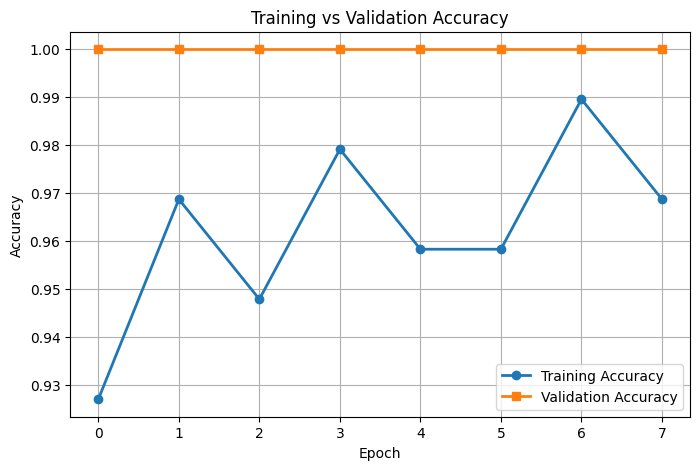

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(
history.history["accuracy"],
marker="o",
linewidth=2,
label="Training Accuracy"
)
plt.plot(
history.history["val_accuracy"],
marker="s",
linewidth=2,
label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
tuner = kt.RandomSearch(
    build_model,
objective="val_loss",
max_trials=5,
overwrite=True,
directory="Regression_Tuning",
project_name="CaliforniaHousing"
)

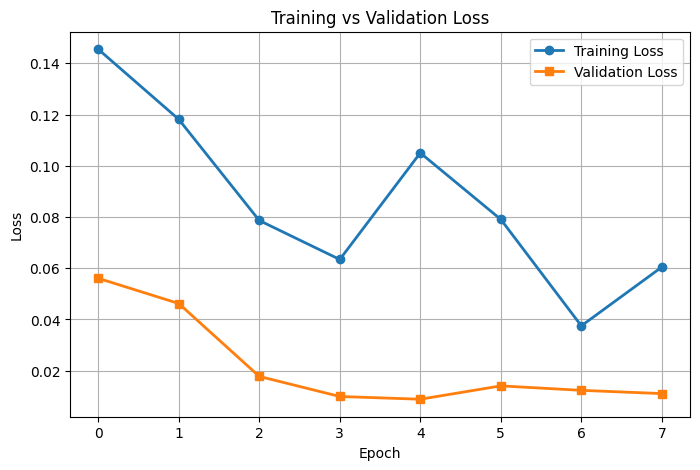

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(
history.history["loss"],
marker="o",
linewidth=2,
label="Training Loss"
)
plt.plot(
history.history["val_loss"],
marker="s",
linewidth=2,
label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
predictions = best_model.predict(X_test)
predicted_classes = np.argmax(predictions, axis=1)
print("Predicted Classes:")
print(predicted_classes)

print("\nActual Classes:")
print(y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step
Predicted Classes:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]

Actual Classes:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


In [ ]:
best_model = tuner.get_best_models(1)[0]
print("\nBest Hyperparameters\n")
best_hp = tuner.get_best_hyperparameters(1)[0]
print(best_hp.values)


Best Hyperparameters

{'units': 96, 'dropout': 0.2, 'hidden_layers': 1, 'units_0': 64, 'optimizer': 'adam', 'learning_rate': 0.001, 'units_1': 96}


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
history = best_model.fit(
  X_train,
  y_train,
  validation_split=0.20,
  epochs=15,
  batch_size=32,
  verbose=1
)

Epoch 1/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - loss: 72.4901 - mae: 3.9187 - val_loss: 24.4445 - val_mae: 2.3006
Epoch 2/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 23.5249 - mae: 2.7927 - val_loss: 9.4309 - val_mae: 1.6240
Epoch 3/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 5.5417 - mae: 1.4221 - val_loss: 2.3234 - val_mae: 0.8180
Epoch 4/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 4.8245 - mae: 1.2846 - val_loss: 6.7792 - val_mae: 1.1455
Epoch 5/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 3.7867 - mae: 1.1465 - val_loss: 1.2949 - val_mae: 0.8034
Epoch 6/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 3.3468 - mae: 1.1290 - val_loss: 1.0939 - val_mae: 0.7315
Epoch 7/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 1.9790 - mae: 0.9303 - val_loss: 0.9304 - val_mae: 0.7221
Epoch 8/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 3.2087 - mae: 0.9741 - val_loss: 12.2046 - val_mae: 1.6804
Epoch 9/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step

In [ ]:
loss, mae = best_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nTest MSE :", loss)
print("Test MAE :", mae)

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9536 - mae: 0.6709

Test MSE : 0.9535521268844604
Test MAE : 0.6708582639694214


In [ ]:
predictions = best_model.predict(X_test)

predictions_original = y_scaler.inverse_transform(predictions)
actual_original = y_scaler.inverse_transform(y_test)

comparison = pd.DataFrame({
    "Actual": actual_original.flatten()[:10],
    "Predicted": predictions_original.flatten()[:10]
})

print(comparison)

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


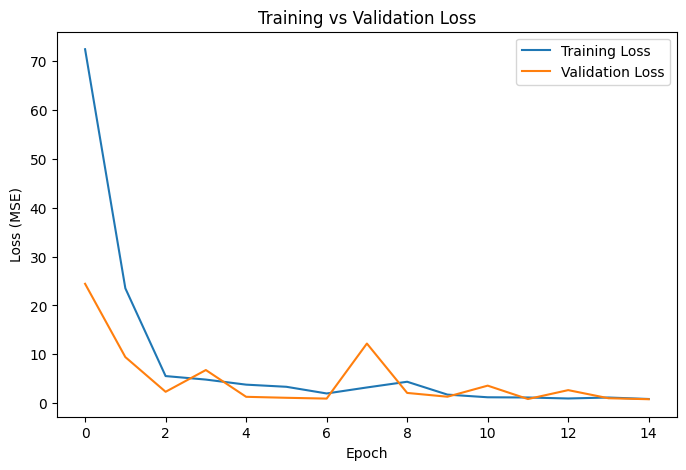

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

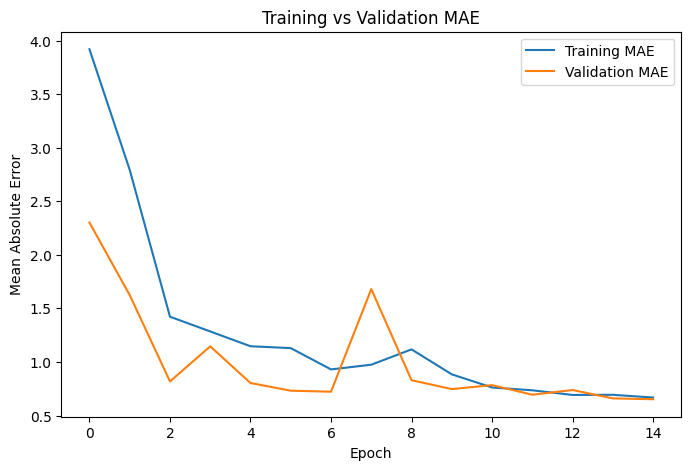

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(
history.history["mae"],
label="Training MAE"
)
plt.plot(
history.history["val_mae"],
label="Validation MAE"
)
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error")
plt.title("Training vs Validation MAE")
plt.legend()
plt.show()